<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados
## Trabalho Prático II: Modelagem de Dados

_Professor Dr. Marco Cristo_

**Alunos:**  `Sarah Lima, Ruan Sathler` <br>
**E-mail:** `sarah.lima@icomp.ufam.edu.br, ruan.sathler@icomp.ufam.edu.br`

In [ ]:
# Imports
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os
import shap

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import StratifiedKFold, HalvingGridSearchCV, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from scipy.stats import wilcoxon

In [ ]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)

Python 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
--------
Pandas: 2.2.2
Numpy: 2.0.2
SKLearn: 1.6.1


#### __Preliminares__: Inicialmente, vamos preparar os dados conforme estabelecido no primeiro trabalho prático. Para tanto, obtenha os dados das cidades dos membros da sua equipe no diretório `data`.

In [ ]:
DATA_PQT = 'data/enem2019.parquet'
MUNICIPIOS = ['São José dos Campos', 'Santa Maria'] # Use o que foi especificado para os membros da sua equipe.

In [ ]:
# Caminho do arquivo
df_enem = pd.read_parquet(DATA_PQT)
df_enem.shape

(599982, 56)

In [ ]:
# Remove todas as instâncias que não possuem valores para as colunas NO_MUNICIPIO_NASCIMENTO ou SG_UF_NASCIMENTO.
# Para as colunas CO_PROVA_CN, CO_PROVA_CH, CO_PROVA_LC, CO_PROVA_MT e TP_STATUS_REDACAO, remove apenas as instâncias
# onde todos esses valores encontram-se ausentes.
crit = ((df_enem.CO_PROVA_CN.isnull())&(df_enem.CO_PROVA_CH.isnull())&
        (df_enem.CO_PROVA_LC.isnull())&(df_enem.CO_PROVA_MT.isnull())&
        (df_enem.TP_STATUS_REDACAO.isnull()))
df_enem = df_enem[~crit]
display(df_enem.shape)

notas = [c for c in df_enem.columns if 'NU_NOTA' in c]
for c in notas:
    df_enem[c] = df_enem[c].fillna(0)

cods = [c for c in df_enem.columns if 'CO_PROVA' in c]
for c in cods:
    df_enem[c] = df_enem[c].fillna(500)

# Usando campo NU_IDADE, é criado FAIXA_ETARIA com os seguintes intervalos
# Instâncias com idade inferior a 10 ou superior a 100 anos sao removidas
def to_faixas(idade):
    if idade<18: return '10-18'
    elif idade<22: return '18-22'
    elif idade<26: return '22-26'
    elif idade<33: return '26-33'
    elif idade<40: return '33-40'
    elif idade<55: return '40-55'
    elif idade<63: return '55-65'
    elif idade<70: return '65-70'
    else: return '70-100'

df_enem = df_enem[(df_enem.NU_IDADE>=10)&(df_enem.NU_IDADE<=100)]
df_enem['FAIXA_ETARIA'] = df_enem.NU_IDADE.apply(to_faixas)

display(df_enem.FAIXA_ETARIA.value_counts())

nota_media = df_enem.NU_NOTA_REDACAO.mean()

# Criação da variável binária TARGET
df_enem['TARGET'] = df_enem.NU_NOTA_REDACAO.apply(lambda v: 1 if v>nota_media else 0)

cols_to_use = ['FAIXA_ETARIA', 'NO_MUNICIPIO_RESIDENCIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
               'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'CO_PROVA_CH',
               'CO_PROVA_LC', 'NU_NOTA_CH', 'NU_NOTA_LC', 'TP_LINGUA', 'Q001',
               'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q021', 'Q022', 'Q024', 'Q025']

df_enem_c = df_enem[df_enem.NO_MUNICIPIO_PROVA.isin(MUNICIPIOS)][cols_to_use + ['TARGET']].copy()

(461570, 56)

,count
FAIXA_ETARIA,
18-22,193068
10-18,121679
22-26,59240
26-33,42011
33-40,22444
40-55,20065
55-65,2462
65-70,495
70-100,99


<div class="alert alert-info" >
<b>1 - MODELAGEM:</b> Usando o dataset <b>df_enem_c</b>, o seu objetivo é prever que alunos vão obter uma nota na redação acima da nota média observada nas cidades associadas com a sua equipe. Para tanto, prepare um pipeline de comparação justo entre os métodos, onde:
    
- Variáveis categóricas devem ser codificadas com One-hot;
- Variáveis numéricas devem ser padronizadas (z-score);
- Todos os métodos comparados devem ser otimizados (usando uma ténica de busca em _grid_ e validação cruzada) de acordo com o conjunto _mínimo_ de hiper-parâmetros descritos na tabela abaixo:

| Método | Número mínimo de parâmetros a serem avaliados |
|-----------|-------|
| __Naive Bayes__ |  |
| __Logistic Regression__ | - __C__: 0.1, 1, 10<br>- __penalty__: L2<br>- __solver__: lbfgs, liblinear |
| __Decision Tree__ | - __max_depth__: None, 8, 16<br>- __min_samples_leaf__: 1, 5, 18 |
| __Support Vector Machine__ | - __C__: 0.5, 1, 4<br>- __kernel__: linear, rbf<br>- __gamma__: scale |
| __Neural Network__ | - __hidden_layer_sizes__: (64,), (128,)<br>- __activation__: relu, tanh<br>- __alpha__: 1e-4, 1e-3<br>- __learning_rate_init__: 1e-3 |
| __Random Forest__ | - __n_estimators__: 200, 400<br>- __max_depth__: None, 12<br>- __min_samples_leaf__: 1, 5 |
| __Gradient Boosting__ | - __learning_rate__: 0.05, 0.1<br>- __max_depth__: None, 8, 16<br>- __l2_regularization__: 0.0, 1.0 |

<b>2 - AVALIAÇÃO COMPARATIVA:</b> Os resultados devem ser comparados usando as métricas __Acurácia__, __F1__ e __AUC__. Em particular, todos os métodos devem ser comparados entre si quanto à significância estatística das diferenças entre os AUCs obtidos. Para isso, use o teste não paramétrico de Wilcoxon. Ao fim, as seguintes tabelas devem ser preenchidas:

| Método | Acurácia | F1 | AUC |
|--------|----------|----|-----|
| Naive Bayes |  |  |  |
| Logistic Regression |  |  |  |
| Decision Tree |  |  |  |
| SVM |  |  |  |
| Neural Networks |  |  |  |
| Random Forest |  |  |  |
| Gradient Boosting |  |  |  |


| Método 1 | Método 2 | p-value (diferença de AUCs) |
|-----------|-------|-------|
| Naive Bayes | Logistic Regression |  |
| Naive Bayes | Decision Tree |  |
| Naive Bayes | SVM |  |
| Naive Bayes | Neural Networks |  |
| Naive Bayes | Random Forest |  |
| Naive Bayes | Gradient Boosting |  |
| Logistic Regression  | Decision Tree |  |
| Logistic Regression | SVM |  |
| Logistic Regression | Neural Networks |  |
| Logistic Regression  | Random Forest |  |
| Logistic Regression  | Gradient Boosting |  |
| Decision Tree | SVM |  |
| Decision Tree | Neural Networks |  |
| Decision Tree  | Random Forest |  |
| Decision Tree  | Gradient Boosting |  |
| SVM | Neural Networks |  |
| SVM  | Random Forest |  |
| SVM  | Gradient Boosting |  |
| Neural Networks  | Random Forest |  |
| Neural Networks  | Gradient Boosting |  |
| Random Forest  | Gradient Boosting |  |

<b>3 - EXPLICAÇÃO:</b> Finalmente, reporte a contribuição de cada variável usada pelo __melhor modelo__, usando o SHAP (use summary plots). Ao reportar o nome das variáveis, use nomes interpretáveis (ex: EducacaoDePaiOuResponsavel em lugar de Q001)

</div>

# -- Questão 1 --

## Dividindo os dados em treino e teste

In [ ]:
from sklearn.model_selection import train_test_split

X = df_enem_c.drop(columns=['TARGET'])  # Variáveis independentes
y = df_enem_c['TARGET']  # Variável dependente

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
df_enem_c

,FAIXA_ETARIA,NO_MUNICIPIO_RESIDENCIA,TP_SEXO,TP_ESTADO_CIVIL,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,CO_PROVA_CH,CO_PROVA_LC,NU_NOTA_CH,...,Q002,Q003,Q004,Q005,Q006,Q021,Q022,Q024,Q025,TARGET
79996,33-40,Santa Maria,F,1,1,1,1,507.0,511.0,395.7,...,C,A,A,3,B,A,B,A,A,1
79997,18-22,Pejuçara,F,1,1,3,1,507.0,511.0,648.7,...,G,D,D,2,F,A,C,B,A,1
79999,18-22,Jari,F,1,1,4,1,508.0,512.0,526.2,...,E,B,B,3,G,A,D,A,B,1
80000,33-40,Santa Maria,M,0,1,13,1,508.0,512.0,505.4,...,E,F,C,6,E,B,B,B,B,0
80001,26-33,Santa Maria,M,0,1,13,1,509.0,514.0,618.9,...,D,A,A,2,K,A,C,C,B,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489978,26-33,São José dos Campos,F,1,1,12,1,508.0,512.0,618.0,...,F,B,D,3,C,A,E,C,B,1
489979,10-18,São José dos Campos,M,1,2,0,2,509.0,514.0,562.3,...,E,D,D,3,L,B,D,B,B,0
489980,26-33,São José dos Campos,M,1,1,12,1,509.0,514.0,625.6,...,E,C,A,2,B,A,B,B,B,0
489981,10-18,São José dos Campos,M,1,2,0,2,508.0,512.0,511.5,...,E,D,D,4,F,A,D,A,B,1


## Pré-processamento

In [ ]:
# Identificando variáveis categóricas e numéricas
cat_cols = ["FAIXA_ETARIA", "NO_MUNICIPIO_RESIDENCIA", "TP_SEXO",
    "TP_ESTADO_CIVIL", "TP_ST_CONCLUSAO", "TP_ANO_CONCLUIU", "TP_ESCOLA",
    "Q002","Q003","Q004","Q005","Q006","Q021","Q022","Q024","Q025"
]
num_cols = ["CO_PROVA_CH", "CO_PROVA_LC","NU_NOTA_CH"]

# Pré-processador
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), cat_cols)
])

## Modelos

In [ ]:
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

modelos = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42),
    'SVC': SVC(probability=True, random_state=42),
    'NaiveBayes': GaussianNB(),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'NeuralNetwork': MLPClassifier(max_iter=500, random_state=42)
}

## Pipelines

In [ ]:
# Função para converter colunas numéricas para float32
def to_float32(X):
    X_copy = X.copy()
    X_copy[num_cols] = X_copy[num_cols].astype('float32')
    return X_copy

# Criando pipelines para cada modelo, integrando FunctionTransformer
pipelines = {
    nome: Pipeline(steps=[
        ('to_float32', FunctionTransformer(to_float32, validate=False)),
        ('preprocessamento', preprocessor),
        ('modelo', modelo)
    ])
    for nome, modelo in modelos.items()
}

In [ ]:
# Dicionário de parametros para os modelos
param_grids = {
    'LogisticRegression': {
        'modelo__C': [0.1, 1, 10],
        'modelo__penalty': ['l2'],
        'modelo__solver': ['lbfgs', 'liblinear']
    },
    'DecisionTree': {
        'modelo__max_depth': [None, 8, 16],
        'modelo__min_samples_leaf': [1, 5, 18]
    },
    'RandomForest': {
        'modelo__n_estimators': [200, 400],
        'modelo__max_depth': [None, 12],
        'modelo__min_samples_leaf': [1, 5]
    },
    'SVC': {
        'modelo__C': [0.5, 1, 4],
        'modelo__kernel': ['linear', 'rbf'],
        'modelo__gamma': ['scale']
    },
    'NaiveBayes': {
        'modelo__var_smoothing': [1e-9, 1e-8, 1e-7]
    },
    'GradientBoosting': {
    'modelo__learning_rate': [0.05, 0.1],
    'modelo__max_depth': [3, 8, 16],
    'modelo__l2_regularization': [0.0, 1.0],
    'modelo__n_estimators': [100, 200],
    'modelo__subsample': [0.8, 1.0]
    }
    ,
    'NeuralNetwork': {
        'modelo__hidden_layer_sizes': [(64,), (128,)],
        'modelo__activation': ['relu', 'tanh'],
        'modelo__alpha': [1e-4, 1e-3],
        'modelo__learning_rate_init': [1e-3]
    }
}

## Avaliação com Validação Cruzada
osb: o treinamento desses modelos e sua validação já estão salvos e podem ser recuperados no tópico a seguir

In [ ]:
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, HalvingGridSearchCV
import time

# 1. CV Rápido para encontrar Hiperparâmetros
cv_search = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. CV Robusto para Estatística
# Isso gera 30 pontos de dados (10 folds x 3 repetições),
cv_eval = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=42)

# Busca de hiperparâmetros
search_results = {}

print(f"--- Iniciando a busca de hiperparâmetros para {len(pipelines)} modelos ---")

for nome, pipe in pipelines.items():
    # 1. Marca o tempo inicial
    start = time.time()

    print(f"\n" + "="*50)
    print(f"PROCESSANDO MODELO: {nome}")
    print("="*50)

    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids[nome],
        cv=cv_search,  # O seu CV rápido
        scoring='accuracy',
        factor=2,
        n_jobs=-1,
        refit=True,
        random_state=42,
        verbose=1  # <--- MUDANÇA CRÍTICA: Mostra o progresso interno!
    )

    # Onde a mágica (e a demora) acontece
    search.fit(X, y)

    # 2. Calcula quanto tempo demorou
    end = time.time()
    elapsed_min = (end - start) / 60

    print(f"-> Concluído: {nome}")
    print(f"-> Tempo gasto: {elapsed_min:.2f} minutos")
    print(f"-> Melhor Acurácia encontrada: {search.best_score_:.4f}")

    search_results[nome] = search

print("\n--- FIM DA OTIMIZAÇÃO DE TODOS OS MODELOS ---")


--- Iniciando a busca de hiperparâmetros para 7 modelos ---

PROCESSANDO MODELO: LogisticRegression
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 3821
max_resources_: 15285
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 6
n_resources: 3821
Fitting 3 folds for each of 6 candidates, totalling 18 fits
----------
iter: 1
n_candidates: 3
n_resources: 7642
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 2
n_candidates: 2
n_resources: 15284
Fitting 3 folds for each of 2 candidates, totalling 6 fits
-> Concluído: LogisticRegression
-> Tempo gasto: 0.25 minutos
-> Melhor Acurácia encontrada: 0.7634

PROCESSANDO MODELO: DecisionTree
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 1910
max_resources_: 15285
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 9
n_resources: 1910
Fitting 3 folds for each of 9 candidates, totalling 27 fits
----------
iter: 

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# Avaliação Estatística
resultados = {}

print("--- Iniciando Validação Cruzada Robusta ---")

for nome, search in search_results.items():

    start_time = time.time()

    print(f"Avaliando modelo: {nome}...", end=" ", flush=True)

    best_pipe = search.best_estimator_

    # --- Nucleo ---
    scores = cross_validate(
        best_pipe, X, y,
        cv=cv_eval,
        scoring=['accuracy', 'f1', 'roc_auc'],
        return_estimator=True, n_jobs=-1
    )
    # ------------------------------------------------

    #calculo de tempo
    elapsed = time.time() - start_time
    print(f"Concluído em {elapsed:.1f} segundos.")

    resultados[nome] = {
        'best_params': search.best_params_,
        'accuracy_mean': np.mean(scores['test_accuracy']),
        'f1_mean': np.mean(scores['test_f1']),
        'roc_auc_mean': np.mean(scores['test_roc_auc']),
        'auc_fold': scores['test_roc_auc'],
        'estimators': scores['estimator']
    }

--- Iniciando Validação Cruzada Robusta ---
Avaliando modelo: LogisticRegression... Concluído em 15.4 segundos.
Avaliando modelo: DecisionTree... Concluído em 12.5 segundos.
Avaliando modelo: RandomForest... Concluído em 201.3 segundos.
Avaliando modelo: SVC... Concluído em 5425.5 segundos.
Avaliando modelo: NaiveBayes... Concluído em 9.2 segundos.
Avaliando modelo: GradientBoosting... Concluído em 297.7 segundos.
Avaliando modelo: NeuralNetwork... Concluído em 1407.9 segundos.


### 💾 Salvamento e Checkpoint dos Modelos

Visando garantir a integridade do processamento realizado, executamos a persistência dos artefatos. Todos os modelos otimizados via HalvingGridSearchCV são serializados e salvos externamente. Esta etapa é crucial para assegurar a reprodutibilidade científica 🧪 e permitir futuras validações estatísticas 📊 sem o custo computacional de um novo treinamento.

In [ ]:
import joblib
import os
from google.colab import files

# --- 1. SALVAMENTO DOS DADOS ---
# Define o caminho local (pasta temporária do Colab)
caminho_local = 'data'
os.makedirs(caminho_local, exist_ok=True)
nome_arquivo = f'{caminho_local}/modelos_otimizados.pkl'

print(f"💾 Salvando modelos em '{nome_arquivo}'...")
joblib.dump(search_results, nome_arquivo)

# Verifica o tamanho para garantir
tamanho_mb = os.path.getsize(nome_arquivo) / (1024 * 1024)
print(f"✅ Arquivo salvo com sucesso! Tamanho: {tamanho_mb:.2f} MB")
print("-" * 50)

# --- 2. CRIAÇÃO DA TABELA DE RESUMO ---
print("📊 Gerando tabela de performance da Otimização (Best Params)...")

resumo_dados = []

for nome, search in search_results.items():
    resumo_dados.append({
        'Modelo': nome,
        'Acurácia (Validação)': search.best_score_,  # Nota obtida durante o GridSearch (CV=3)
        'Melhores Parâmetros': search.best_params_
    })

# Cria o DataFrame e ordena do melhor para o pior
df_resumo = pd.DataFrame(resumo_dados).sort_values(by='Acurácia (Validação)', ascending=False)

# Melhora a formatação da tabela
pd.set_option('display.max_colwidth', 100) # Para ver os parâmetros inteiros
pd.set_option('display.float_format', '{:.4f}'.format) # 4 casas decimais

# Exibe a tabela
display(df_resumo)

print("\n⚠️ NOTA: Esta acurácia é a média obtida durante a busca de hiperparâmetros (CV=3).")

💾 Salvando modelos em 'sample_data/data/modelos_otimizados.pkl'...
✅ Arquivo salvo com sucesso! Tamanho: 45.71 MB
--------------------------------------------------
📊 Gerando tabela de performance da Otimização (Best Params)...


,Modelo,Acurácia (Validação),Melhores Parâmetros
0,LogisticRegression,0.7634,"{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}"
5,GradientBoosting,0.7633,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 200, 'modelo__su..."
3,SVC,0.7617,"{'modelo__C': 1, 'modelo__gamma': 'scale', 'modelo__kernel': 'linear'}"
2,RandomForest,0.7599,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}"
1,DecisionTree,0.7441,"{'modelo__max_depth': 8, 'modelo__min_samples_leaf': 18}"
6,NeuralNetwork,0.6980,"{'modelo__activation': 'tanh', 'modelo__alpha': 0.001, 'modelo__hidden_layer_sizes': (64,), 'mod..."
4,NaiveBayes,0.6810,{'modelo__var_smoothing': 1e-08}



⚠️ NOTA: Esta acurácia é a média obtida durante a busca de hiperparâmetros (CV=3).


In [52]:
import joblib
import os
import gdown

# --- CONFIGURAÇÃO ---
#     CARREGAMENTO DOS MODELOS
# O ID do arquivo é a parte estranha no meio do seu link
file_id = '1eb2GtRaRjojrBc8la4_dpXedgkQmoqj5'
url = f'https://drive.google.com/uc?id={file_id}'
output_path = 'modelos_otimizados_baixados.pkl'

# --- 1. DOWNLOAD DO ARQUIVO ---
if not os.path.exists(output_path):
    print("⬇️ Baixando modelos do Google Drive (pode demorar um pouco)...")
    gdown.download(url, output_path, quiet=False)
    print("✅ Download concluído!")
else:
    print("📂 Arquivo já existe, pulando download.")

# --- 2. DEFINIÇÃO DA FUNÇÃO PERSONALIZADA ---
# (Obrigatório para evitar erro de 'AttributeError', lembra?)
def to_float32(x):
    try:
        return x.astype('float32')
    except:
        return x

# --- 3. CARREGAMENTO ---
print("🔄 Carregando modelos para a memória...")
try:
    search_results = joblib.load(output_path)
    print(f"✅ SUCESSO! {len(search_results)} modelos carregados e prontos para uso.")
except Exception as e:
    print(f"❌ Erro ao carregar: {e}")


⬇️ Baixando modelos do Google Drive (pode demorar um pouco)...


Downloading...
From: https://drive.google.com/uc?id=1eb2GtRaRjojrBc8la4_dpXedgkQmoqj5
To: /content/modelos_otimizados_baixados.pkl
100%|██████████| 47.9M/47.9M [00:00<00:00, 218MB/s]


✅ Download concluído!
🔄 Carregando modelos para a memória...
✅ SUCESSO! 7 modelos carregados e prontos para uso.


In [56]:
import joblib
import os

# --- CONFIGURAÇÃO ---
# Caminho da pasta local (temporária do Colab)
caminho_pasta = 'data'
nome_arquivo = f'{caminho_pasta}/resultados_estatisticos.pkl'

# --- SALVAMENTO ---
# 1. Garante que a pasta existe
os.makedirs(caminho_pasta, exist_ok=True)

# 2. Verifica se a variável 'resultados' existe na memória
if 'resultados' in locals():
    print(f"💾 Salvando dados estatísticos em: {nome_arquivo} ...")

    try:
        # Salva o dicionário no arquivo
        joblib.dump(resultados, nome_arquivo)

        # 3. Verificação Final
        if os.path.exists(nome_arquivo):
            tamanho_mb = os.path.getsize(nome_arquivo) / (1024 * 1024)
            print("-" * 40)
            print(f"✅ ARQUIVO SALVO COM SUCESSO!")
            print(f"📂 Local: {nome_arquivo}")
            print(f"📦 Tamanho: {tamanho_mb:.2f} MB")
            print("Dica: Lembre-se de baixar este arquivo ou salvar no Drive antes de fechar o Colab.")
        else:
            print("❌ ERRO: O arquivo não foi encontrado após a tentativa de salvamento.")

    except Exception as e:
        print(f"❌ Erro ao salvar: {e}")
else:
    print("⚠️ AVISO: A variável 'resultados' não foi encontrada na memória.")
    print("Você precisa rodar a célula de 'Avaliação Estatística' antes de salvar.")

💾 Salvando dados estatísticos em: data/resultados_estatisticos.pkl ...
----------------------------------------
✅ ARQUIVO SALVO COM SUCESSO!
📂 Local: data/resultados_estatisticos.pkl
📦 Tamanho: 1303.21 MB
Dica: Lembre-se de baixar este arquivo ou salvar no Drive antes de fechar o Colab.


In [53]:
import joblib
import os
import gdown

# --- CONFIGURAÇÃO ---
# RECUPERAÇÃO DOS TESTES ESTATISTICOS
# ID do arquivo de ESTATÍSTICAS (resultados)
file_id = '1rVDu3ihAQitB_GsMT053KVgrJW2X4j6T'
url = f'https://drive.google.com/uc?id={file_id}'
output_path = 'resultados_estatisticos_baixados.pkl'

# --- 1. DOWNLOAD ---
if not os.path.exists(output_path):
    print("⬇️ Baixando dados estatísticos do Drive...")
    gdown.download(url, output_path, quiet=False)
    print("✅ Download concluído!")
else:
    print("📂 Arquivo já existe.")

# --- 2. CARREGAMENTO ---
print("🔄 Carregando para a variável 'resultados'...")
try:
    # Carrega direto para a variável que gera as tabelas
    resultados = joblib.load(output_path)

    print("-" * 40)
    print(f"✅ SUCESSO! Dados de {len(resultados)} modelos recuperados.")
    print("Agora você pode rodar as células da Tabela 1, Tabela 2 (Wilcoxon) e Gráficos.")

except Exception as e:
    print(f"❌ Erro ao carregar: {e}")

⬇️ Baixando dados estatísticos do Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1rVDu3ihAQitB_GsMT053KVgrJW2X4j6T
From (redirected): https://drive.google.com/uc?id=1rVDu3ihAQitB_GsMT053KVgrJW2X4j6T&confirm=t&uuid=538e0ac9-a3e3-41b2-8800-eb9242e47e04
To: /content/resultados_estatisticos_baixados.pkl
100%|██████████| 1.37G/1.37G [00:19<00:00, 68.5MB/s]


✅ Download concluído!
🔄 Carregando para a variável 'resultados'...
----------------------------------------
✅ SUCESSO! Dados de 7 modelos recuperados.
Agora você pode rodar as células da Tabela 1, Tabela 2 (Wilcoxon) e Gráficos.


#### Otimizações para Reduzir Custo Computacional e Memória
- **Representação Numérica**: Os dados numéricos foram convertidos para `float32` para economizar memória.
- **OneHotEncoder**: Foi usado `min_frequency=50` e `handle_unknown='infrequent_if_exist'` para reduzir o número de categorias codificadas.
- **Validação Cruzada**: Foi usada validação cruzada interna com `cv=3` para a busca de hiperparâmetros, reduzindo o custo de execução.
- **Paralelismo**: Configurado para não retornar estimadores na validação cruzada externa, economizando memória.


## Comparação usando Wilcoxon

In [ ]:
model_names = list(resultados.keys())
pairs = []
for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        a = model_names[i]
        b = model_names[j]
        stat, p = wilcoxon(resultados[a]['auc_fold'], resultados[b]['auc_fold'])
        pairs.append({'modelo_A': a, 'modelo_B': b, 'stat': stat, 'p_value': p})

tabela_wilcoxon = pd.DataFrame(pairs).sort_values('p_value')
print("\n - O teste de Wilcoxon foi usado para comparar os AUCs entre os modelos. Um p-valor baixo indica diferença significativa.")
tabela_wilcoxon


 - O teste de Wilcoxon foi usado para comparar os AUCs entre os modelos. Um p-valor baixo indica diferença significativa.


,modelo_A,modelo_B,stat,p_value
0,LogisticRegression,DecisionTree,0.0,1.862645e-09
3,LogisticRegression,NaiveBayes,0.0,1.862645e-09
6,DecisionTree,RandomForest,0.0,1.862645e-09
5,LogisticRegression,NeuralNetwork,0.0,1.862645e-09
7,DecisionTree,SVC,0.0,1.862645e-09
10,DecisionTree,NeuralNetwork,0.0,1.862645e-09
9,DecisionTree,GradientBoosting,0.0,1.862645e-09
8,DecisionTree,NaiveBayes,0.0,1.862645e-09
14,RandomForest,NeuralNetwork,0.0,1.862645e-09
13,RandomForest,GradientBoosting,0.0,1.862645e-09


In [ ]:
from scipy.stats import wilcoxon

# ==============================================================================
# TABELA 1: MÉTRICAS (Acurácia, F1, AUC)
# ==============================================================================
print("--- TABELA 1: DESEMPENHO DOS MODELOS ---")

dados_tabela1 = []

# Ordem sugerida na sua pergunta (pode variar se seus nomes forem diferentes no código)
ordem_desejada = [
    'NaiveBayes', 'LogisticRegression', 'DecisionTree', 'SVC',
    'NeuralNetwork', 'RandomForest', 'GradientBoosting'
]

# Verifica se os nomes batem com o seu dicionário, senão usa os que tem
modelos_disponiveis = list(resultados.keys())

for nome in modelos_disponiveis:
    dados_tabela1.append({
        'Método': nome,
        'Acurácia': f"{resultados[nome]['accuracy_mean']:.4f}",
        'F1': f"{resultados[nome]['f1_mean']:.4f}",
        'AUC': f"{resultados[nome]['roc_auc_mean']:.4f}"
    })

df_tabela1 = pd.DataFrame(dados_tabela1)
display(df_tabela1)

print("\n" + "="*50 + "\n")

# ==============================================================================
# TABELA 2: COMPARAÇÃO ESTATÍSTICA (WILCOXON - AUC)
# ==============================================================================

pares_solicitados = [
    ('NaiveBayes', 'LogisticRegression'),
    ('NaiveBayes', 'DecisionTree'),
    ('NaiveBayes', 'SVC'),
    ('NaiveBayes', 'NeuralNetwork'),
    ('NaiveBayes', 'RandomForest'),
    ('NaiveBayes', 'GradientBoosting'),
    ('LogisticRegression', 'DecisionTree'),
    ('LogisticRegression', 'SVC'),
    ('LogisticRegression', 'NeuralNetwork'),
    ('LogisticRegression', 'RandomForest'),
    ('LogisticRegression', 'GradientBoosting'),
    ('DecisionTree', 'SVC'),
    ('DecisionTree', 'NeuralNetwork'),
    ('DecisionTree', 'RandomForest'),
    ('DecisionTree', 'GradientBoosting'),
    ('SVC', 'NeuralNetwork'),
    ('SVC', 'RandomForest'),
    ('SVC', 'GradientBoosting'),
    ('NeuralNetwork', 'RandomForest'),
    ('NeuralNetwork', 'GradientBoosting'),
    ('RandomForest', 'GradientBoosting')
]

dados_tabela2 = []

for m1, m2 in pares_solicitados:
    if m1 in resultados and m2 in resultados:
        scores_m1 = resultados[m1]['auc_fold']
        scores_m2 = resultados[m2]['auc_fold']

        stat, p = wilcoxon(scores_m1, scores_m2)

        # Formatação para EXATAMENTE 2 casas decimais
        p_fmt = f"{p:.3f}"

        dados_tabela2.append({
            'Método 1': m1,
            'Método 2': m2,
            'p-value': p_fmt
        })
    else:
        dados_tabela2.append({
            'Método 1': m1,
            'Método 2': m2,
            'p-value': "-"
        })

df_tabela2 = pd.DataFrame(dados_tabela2)

# Exibe a tabela
display(df_tabela2)

# Nota explicativa para quem for ler
print("\n" + "="*60)
print("📝 NOTA DE LEITURA:")
print("Os valores foram arredondados para 3 casas decimais.")
print("- Valores mostrados como '0.000' indicam p-valor extremamente baixo (< 0.0005).")
print("- Isso confirma Diferença Estatisticamente Significativa entre os modelos.")
print("="*60)

--- TABELA 1: DESEMPENHO DOS MODELOS ---


,Método,Acurácia,F1,AUC
0,LogisticRegression,0.7641,0.8037,0.8417
1,DecisionTree,0.7438,0.7783,0.8154
2,RandomForest,0.7585,0.7955,0.8328
3,SVC,0.7644,0.8026,0.8419
4,NaiveBayes,0.6790,0.7333,0.7353
5,GradientBoosting,0.7623,0.7959,0.8409
6,NeuralNetwork,0.6905,0.7344,0.7558


,Método 1,Método 2,p-value
0,NaiveBayes,LogisticRegression,0.000
1,NaiveBayes,DecisionTree,0.000
2,NaiveBayes,SVC,0.000
3,NaiveBayes,NeuralNetwork,0.000
4,NaiveBayes,RandomForest,0.000
5,NaiveBayes,GradientBoosting,0.000
6,LogisticRegression,DecisionTree,0.000
7,LogisticRegression,SVC,0.570
8,LogisticRegression,NeuralNetwork,0.000
9,LogisticRegression,RandomForest,0.000



📝 NOTA DE LEITURA:
Os valores foram arredondados para 3 casas decimais.
- Valores mostrados como '0.000' indicam p-valor extremamente baixo (< 0.0005).
- Isso confirma Diferença Estatisticamente Significativa entre os modelos.


#### Avaliação em hold-out e matriz de confusão

Accuracy_test: 0.7498
F1_test: 0.7907
AUC_test: 0.8265


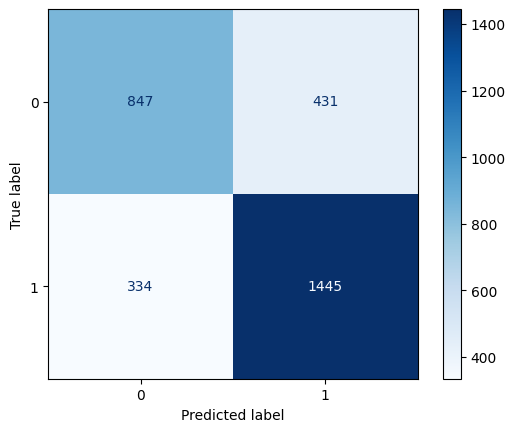

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Escolher melhor pelo AUC médio
melhor = max(resultados.keys(), key=lambda k: resultados[k]['roc_auc_mean'])
best_pipe_final = search_results[melhor].best_estimator_

# Treinar no conjunto de treino
best_pipe_final.fit(X_train, y_train)

# Predições
y_pred = best_pipe_final.predict(X_test)
y_proba = best_pipe_final.predict_proba(X_test)[:, 1]

# Resultados de teste
resultados_teste = {
    'Accuracy_test': accuracy_score(y_test, y_pred),
    'F1_test': f1_score(y_test, y_pred),
    'AUC_test': roc_auc_score(y_test, y_proba)
}

for chave, valor in resultados_teste.items():
    print(f"{chave}: {valor:.4f}")

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.show()

#### Explicação Global - SHAP

Gerando gráfico para: SVC


PermutationExplainer explainer: 101it [09:05,  5.51s/it]
/tmp/ipython-input-2046959535.py:64: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


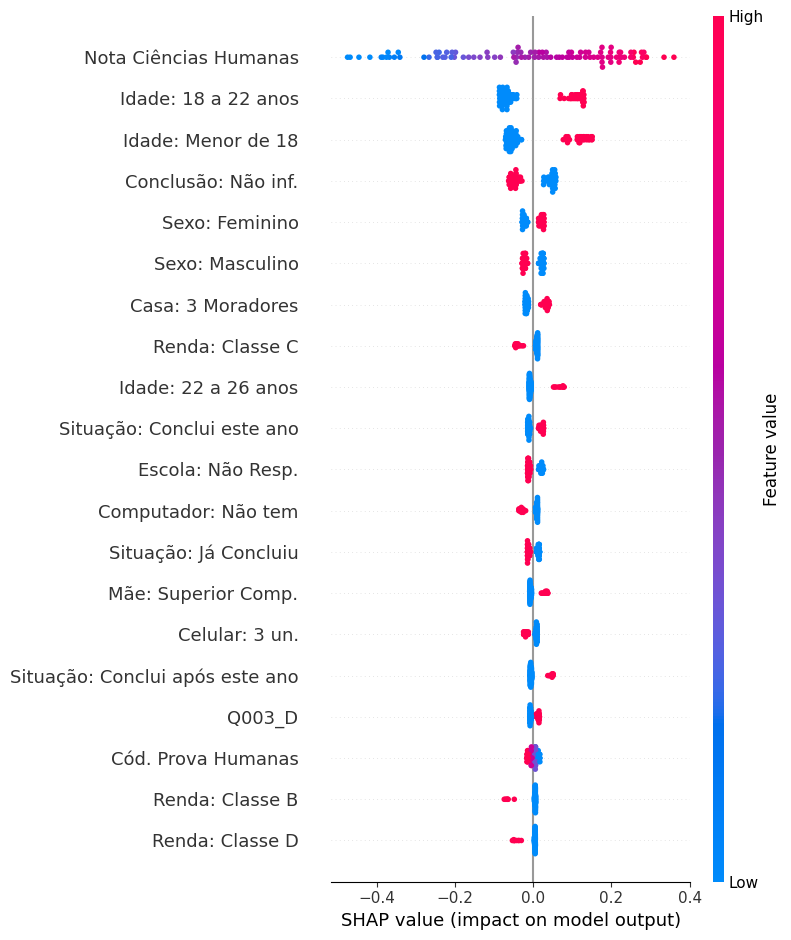

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. Configurações e Dados
modelo_final = best_pipe_final.named_steps['modelo']
pre_processador = best_pipe_final.named_steps['preprocessamento']
X_train_transf = pre_processador.fit_transform(X_train)

# 2. Tratamento dos Nomes (Limpeza + Tradução)
nomes_crus = pre_processador.get_feature_names_out()
nomes_sem_prefixo = [nome.split('__')[-1] for nome in nomes_crus]

# --- DICIONÁRIO ---
mapa_traducao = {
    'NU_NOTA_CH': 'Nota Ciências Humanas',
    'CO_PROVA_CH': 'Cód. Prova Humanas',
    'FAIXA_ETARIA_10-18': 'Idade: Menor de 18',
    'FAIXA_ETARIA_18-22': 'Idade: 18 a 22 anos',
    'FAIXA_ETARIA_22-26': 'Idade: 22 a 26 anos',
    'TP_SEXO_F': 'Sexo: Feminino',
    'TP_SEXO_M': 'Sexo: Masculino',
    'TP_ANO_CONCLUIU_0': 'Conclusão: Não inf.',
    'TP_ST_CONCLUSAO_1': 'Situação: Já Concluiu',
    'TP_ST_CONCLUSAO_2': 'Situação: Conclui este ano',
    'TP_ST_CONCLUSAO_3': 'Situação: Conclui após este ano',
    'TP_ESCOLA_1': 'Escola: Não Resp.',
    'Q005_2': 'Casa: 2 Moradores',
    'Q005_3': 'Casa: 3 Moradores',
    'Q006_B': 'Renda: Classe B',
    'Q006_C': 'Renda: Classe C',
    'Q006_D': 'Renda: Classe D',
    'Q024_A': 'Computador: Não tem',
    'Q022_D': 'Celular: 3 un.',
    'Q002_F': 'Mãe: Superior Comp.'
}

# Aplica a tradução
nomes_finais = [mapa_traducao.get(n, n) for n in nomes_sem_prefixo]

# 3. Cálculo Rápido (Amostra de 100)
#fazer com as amostras complestas estava demorando em torno de 17h, reduzimos para 100
X_amostra = X_train_transf[:100]

print(f"Gerando gráfico para: {type(modelo_final).__name__}")

# Seleção automática do Explainer
if isinstance(modelo_final, (RandomForestClassifier, DecisionTreeClassifier)):
    explainer = shap.TreeExplainer(modelo_final)
    shap_values = explainer.shap_values(X_amostra)
    if isinstance(shap_values, list): shap_values = shap_values[1] # Classe Positiva

elif isinstance(modelo_final, LogisticRegression):
    masker = shap.maskers.Independent(X_train_transf, max_samples=100)
    explainer = shap.LinearExplainer(modelo_final, masker)
    shap_values = explainer(X_amostra)

else:
    # Para SVM, KNN, Neural Network
    explainer = shap.Explainer(modelo_final.predict_proba, X_amostra)
    shap_values = explainer(X_amostra)
    if len(shap_values.shape) == 3: shap_values = shap_values[:, :, 1]

# 4. Plot Final
plt.figure()
shap.summary_plot(
    shap_values,
    X_amostra,
    feature_names=nomes_finais, # Nomes bonitos aqui!
    show=True
)